In [2]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.20.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
import os
import json

# Replace these with your Kaggle credentials
KAGGLE_USERNAME = "ML"
KAGGLE_KEY = "KGAT_ac6700526c56e46cfada7b0832e8bc57"

# Create the .kaggle directory
os.makedirs('/root/.kaggle', exist_ok=True)

# Create kaggle.json
kaggle_token = {
    "username": KAGGLE_USERNAME,
    "key": KAGGLE_KEY
}

with open('/root/.kaggle/kaggle.json', 'w') as f:
    json.dump(kaggle_token, f)

# Set correct permissions
os.chmod('/root/.kaggle/kaggle.json', 0o600)

print("✅ Kaggle API configured successfully!")

✅ Kaggle API configured successfully!


In [5]:
!kaggle datasets list

ref                                                             title                                                 size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  ----------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
rauffauzanrambe/fifa-world-cup-2026-player-performance-dataset  FIFA World Cup 2026 Player Performance Dataset     4154062  2026-06-10 12:58:47.093000          11874        285                1  
mann14/2026-fifa-world-cup                                      2026 FIFA World Cup                                   2905  2026-07-12 14:12:19.273000            756         21                1  
ashyou09/global-budget-allocation-dataset-19362026              Global Budget Allocation Dataset (1936–2026) 🌎      295046  2026-07-11 08:11:16.587000            567         25                1  
abbas829/ecommerce-s

In [6]:
!kaggle datasets download -d vipoooool/new-plant-diseases-dataset

Dataset URL: https://www.kaggle.com/datasets/vipoooool/new-plant-diseases-dataset
License(s): copyright-authors
new-plant-diseases-dataset.zip: Skipping, found more recently modified local copy (use --force to force download)


In [7]:
!unzip -q new-plant-diseases-dataset.zip -d dataset

replace dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [8]:
import os

os.listdir("dataset")

['new plant diseases dataset(augmented)',
 'New Plant Diseases Dataset(Augmented)',
 'test']

In [9]:
import os

dataset_path = "dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)"

print(os.listdir(dataset_path))

['train', 'valid']


In [10]:
train_path = dataset_path + "/train"

classes = sorted(os.listdir(train_path))

print("Total Classes:", len(classes))
print(classes)

Total Classes: 38
['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', '

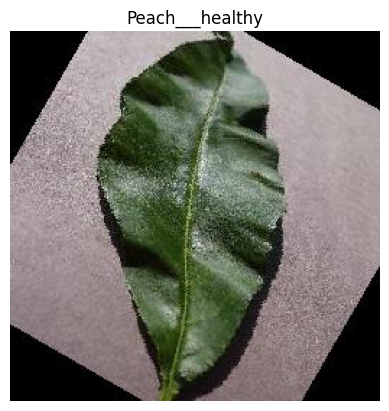

In [11]:
import matplotlib.pyplot as plt
from PIL import Image
import random

sample_class = random.choice(classes)

sample_folder = os.path.join(train_path, sample_class)

sample_image = random.choice(os.listdir(sample_folder))

img = Image.open(os.path.join(sample_folder, sample_image))

plt.imshow(img)
plt.title(sample_class)
plt.axis("off")
plt.show()

In [12]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np
import os

In [23]:
IMAGE_SIZE = (160,160)
BATCH_SIZE = 8

In [24]:
train_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    train_path,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

Found 70295 files belonging to 38 classes.


In [25]:
valid_path = dataset_path + "/valid"

print(valid_path)

dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid


In [26]:
validation_dataset = tf.keras.preprocessing.image_dataset_from_directory(
    valid_path,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 17572 files belonging to 38 classes.


In [27]:
class_names = train_dataset.class_names

print(class_names)

['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry_(including_sour)___Powdery_mildew', 'Cherry_(including_sour)___healthy', 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot', 'Corn_(maize)___Common_rust_', 'Corn_(maize)___Northern_Leaf_Blight', 'Corn_(maize)___healthy', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Grape___healthy', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___Leaf_scorch', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Tomato___Septoria_leaf_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Tomato___Target_Sp

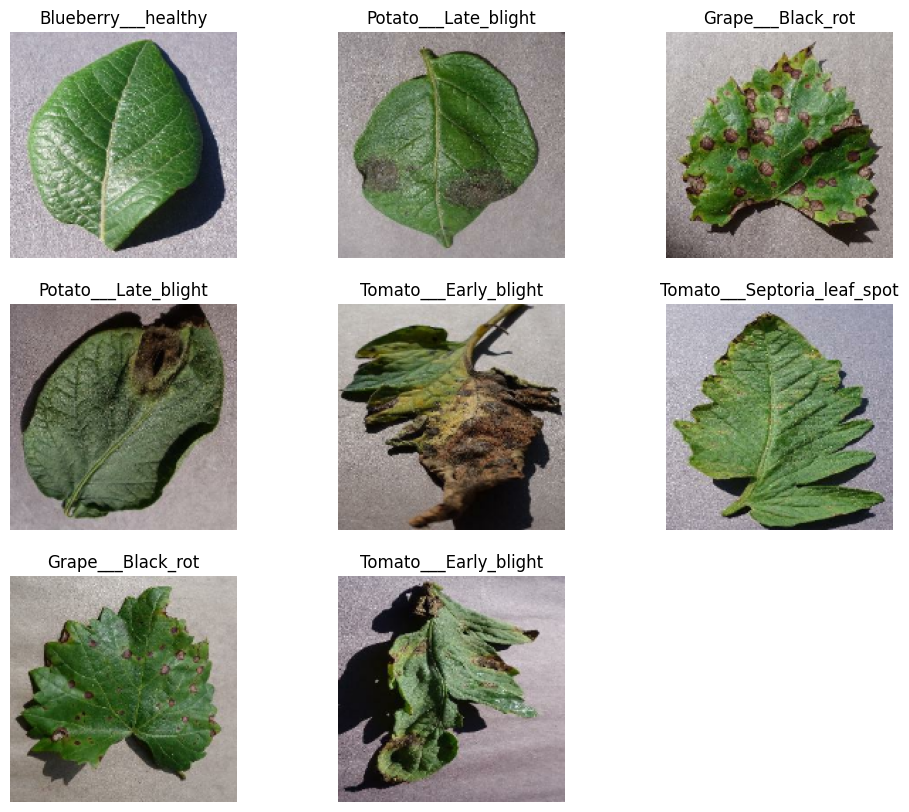

In [28]:
plt.figure(figsize=(12,10))

for images, labels in train_dataset.take(1):

    for i in range(min(9, len(images))):

        ax = plt.subplot(3,3,i+1)

        plt.imshow(images[i].numpy().astype("uint8"))

        plt.title(class_names[labels[i]])

        plt.axis("off")

In [29]:
AUTOTUNE = tf.data.AUTOTUNE

train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)

validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)

In [30]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_dataset = train_dataset.map(
    lambda x, y: (normalization_layer(x), y)
)

validation_dataset = validation_dataset.map(
    lambda x, y: (normalization_layer(x), y)

  )

In [31]:
for images, labels in train_dataset.take(1):
    print(images[0].numpy().min())
    print(images[0].numpy().max())

0.00082354323
0.8589803


In [32]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.2),
    tf.keras.layers.RandomZoom(0.2),
    tf.keras.layers.RandomContrast(0.2)
])

In [38]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(160,160,3),
    include_top=False,
    weights="imagenet"
)

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


In [39]:
base_model.trainable = False

In [40]:
from tensorflow.keras import layers, models

model = models.Sequential([

    data_augmentation,

    layers.Input(shape=(224,224,3)),

    base_model,

    layers.GlobalAveragePooling2D(),

    layers.Dropout(0.3),

    layers.Dense(256, activation="relu"),

    layers.Dropout(0.2),

    layers.Dense(len(class_names), activation="softmax")

])

In [41]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [42]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ ?                      │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

In [43]:
from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(224,224,3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

In [44]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [45]:
import keras
import tensorflow as tf

print("TensorFlow:", tf.__version__)
print("Keras:", keras.__version__)

TensorFlow: 2.20.0
Keras: 3.13.2


In [46]:
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,595,686 (9.90 MB)

 Trainable params: 337,702 (1.29 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [47]:
print(type(train_dataset))
print(type(validation_dataset))

<class 'tensorflow.python.data.ops.map_op._MapDataset'>
<class 'tensorflow.python.data.ops.map_op._MapDataset'>


In [48]:
for images, labels in train_dataset.take(1):
    print(images.shape)
    print(labels.shape)

(8, 160, 160, 3)
(8,)


In [49]:
print(model.input_shape)

(None, 224, 224, 3)


In [58]:
import tensorflow as tf
from tensorflow.keras import backend as K

K.clear_session()

In [59]:
from tensorflow.keras.applications import MobileNetV2

base_model = MobileNetV2(
    input_shape=(160, 160, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

In [62]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom, RandomContrast

data_augmentation = Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.2),
    RandomZoom(0.2),
    RandomContrast(0.2)
])

In [63]:
print(data_augmentation)

<Sequential name=sequential_1, built=False>


In [64]:
from tensorflow.keras import layers, Model

inputs = layers.Input(shape=(160, 160, 3))

x = data_augmentation(inputs)

x = base_model(x, training=False)

x = layers.GlobalAveragePooling2D()(x)

x = layers.Dropout(0.3)(x)

x = layers.Dense(256, activation="relu")(x)

x = layers.Dropout(0.2)(x)

outputs = layers.Dense(len(class_names), activation="softmax")(x)

model = Model(inputs, outputs)

In [65]:
from tensorflow.keras import layers, models

model = models.Sequential([
    layers.Input(shape=(160,160,3)),
    data_augmentation,
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(256, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(len(class_names), activation="softmax")
])

In [67]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [68]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_1 (Sequential)       │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       327,936 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 38)             │         9,766 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,595,686 (9.90 MB)

 Trainable params: 337,702 (1.29 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [69]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=1
)

8787/8787 ━━━━━━━━━━━━━━━━━━━━ 231s 25ms/step - accuracy: 0.7794 - loss: 0.7092 - val_accuracy: 0.8443 - val_loss: 0.4767


In [70]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "/content/drive/MyDrive/plant_disease_model.keras",
    monitor="val_accuracy",
    save_best_only=True
)

In [72]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=3,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/3
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 217s 25ms/step - accuracy: 0.8390 - loss: 0.5169 - val_accuracy: 0.8568 - val_loss: 0.4523
Epoch 2/3
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 215s 25ms/step - accuracy: 0.8449 - loss: 0.5036 - val_accuracy: 0.8753 - val_loss: 0.3835
Epoch 3/3
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 219s 25ms/step - accuracy: 0.8495 - loss: 0.4933 - val_accuracy: 0.8708 - val_loss: 0.3972


In [73]:
history = model.fit(
    train_dataset,
    validation_data=validation_dataset,
    epochs=5,
    callbacks=[early_stop, checkpoint]
)

Epoch 1/5
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 218s 25ms/step - accuracy: 0.8507 - loss: 0.4931 - val_accuracy: 0.8790 - val_loss: 0.3762
Epoch 2/5
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 218s 25ms/step - accuracy: 0.8546 - loss: 0.4850 - val_accuracy: 0.8804 - val_loss: 0.3786
Epoch 3/5
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 220s 25ms/step - accuracy: 0.8577 - loss: 0.4840 - val_accuracy: 0.8772 - val_loss: 0.4068
Epoch 4/5
8787/8787 ━━━━━━━━━━━━━━━━━━━━ 225s 26ms/step - accuracy: 0.8598 - loss: 0.4780 - val_accuracy: 0.8794 - val_loss: 0.3999


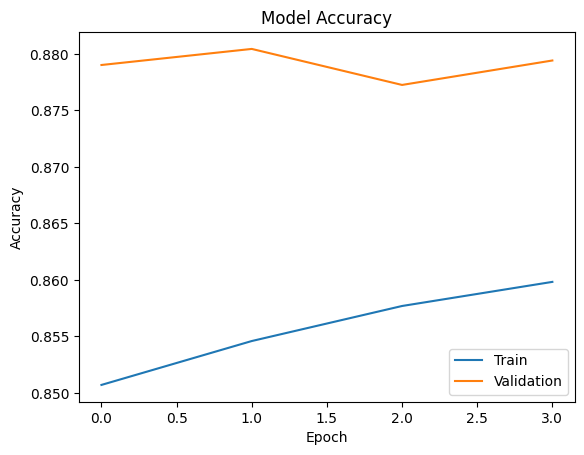

In [74]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend(["Train", "Validation"])
plt.show()

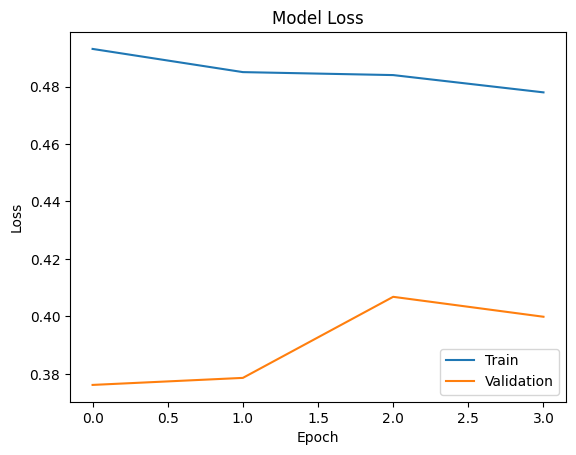

In [75]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title("Model Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend(["Train", "Validation"])
plt.show()

In [76]:
model.save("/content/drive/MyDrive/plant_disease_model.keras")

print("✅ Model Saved Successfully")

✅ Model Saved Successfully


In [77]:
import json

with open("/content/drive/MyDrive/class_names.json", "w") as f:
    json.dump(class_names, f)

print("✅ Class Names Saved Successfully")

✅ Class Names Saved Successfully


In [79]:
from google.colab import files

uploaded = files.upload()

Saving dataset-card.jpg to dataset-card.jpg


In [80]:
from tensorflow.keras.preprocessing import image
import numpy as np

img_path = list(uploaded.keys())[0]

img = image.load_img(img_path, target_size=(160,160))

img_array = image.img_to_array(img)

img_array = np.expand_dims(img_array, axis=0)

img_array = img_array / 255.0

In [81]:
prediction = model.predict(img_array)

predicted_class = class_names[np.argmax(prediction)]

confidence = np.max(prediction) * 100

print("Plant Disease :", predicted_class)

print("Confidence :", round(confidence,2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step
Plant Disease : Tomato___Bacterial_spot
Confidence : 48.21 %


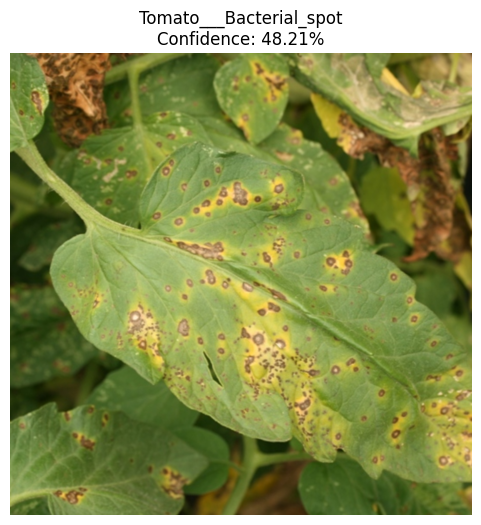

In [82]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.imshow(image.load_img(img_path))

plt.title(f"{predicted_class}\nConfidence: {confidence:.2f}%")

plt.axis("off")

plt.show()

In [83]:
import os

print(os.path.exists("/content/drive/MyDrive/plant_disease_model.keras"))

True
